# Cuaderno 1: Ingeniería de Datos, Deduplicación de Microdatos, Clasificación Semántica y Construcción de Paneles Maestros

**Proyecto:** Impacto del Gasto Educativo Contratado (SECOP) y del Presupuesto General de la Nación (PGN) sobre la Calidad Educativa Oficial en Colombia (2019–2025).

---

### Resumen Metodológico de la Fase de Ingeniería de Datos
Este cuaderno implementa y ejecuta de principio a fin el flujo de depuración, validación y estructuración de los paneles departamental ($N = 231$ observaciones; $33$ departamentos $\times 7$ años) y municipal ($N = 7.714$ observaciones; $1.102$ municipios $\times 7$ años):
1. **Deflactación Macroeconómica Homogénea:** Construcción de la serie oficial del Índice de Precios al Consumidor (IPC DANE, base $2019 = 1,0000$) para expresar toda cifra contractual y presupuestal en pesos constantes de 2019.
2. **Deduplicación Estructural de Microdatos SECOP (2019–2023):** Colapso de procesos multi-beneficiario en SECOP Integrado (que duplicaban $403.375$ registros en 2019, incluyendo convocatorias municipales repetidas más de $200.000$ veces) y de contratos repetidos en SECOP II ($533.403$ filas en 2023), delimitando la ventana válida de contratación a **2019–2023**.
3. **Clasificador Semántico Jerárquico (Niveles A, B y X) y Auditoría de Plausibilidad:** Filtrado exclusivo de entidades de **Orden Territorial**, clasificación homogénea en educación básica y media, desagregación en dos rubros mutuamente excluyentes (**CAPEX/Dotación** vs. **Bienestar/Operación**) y validación frente al catálogo UNSPSC 2023 ($70,97\%$ de *recall* ponderado por valor).
4. **Armonización Censal del ICFES Saber 11 (2019–2025):** Deduplicación por identificador estudiantil (`estu_consecutivo`), recuperación íntegra de los catorce períodos semestrales y filtrado canónico de la población objetivo (`ESTUDIANTE` + `OFICIAL` + `Calendario A`, $N = 2.948.410$ evaluados).
5. **Ensamblaje en Vivo del Panel Maestro sin Sesgo de Razón de Pearson ni Fuga de Información:** Integración sin doble conteo del Programa de Alimentación Escolar (PAE), extracción de indicadores departamentales oficiales de TerriData, fijación del denominador per cápita en la matrícula oficial base pre-pandemia ($N_{i,2019}^{\text{oficial}}$) y verificación de aserciones de calidad.

### 1. Inicialización Portable del Entorno y Serie de Deflactores del IPC (Base 2019 = 1,0000)

Se configuran las librerías de procesamiento relacional (`duckdb`, `pandas`, `numpy`) con resolución dinámica de rutas y se verifica y grafica la serie de deflactores acumulados del IPC oficial del DANE.

In [1]:
import os
import re
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, HTML

sns.set_theme(style='whitegrid', font='sans-serif')
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 40)
pd.set_option('display.float_format', '{:,.4f}'.format)

def resolve_project_root() -> Path:
    """Resuelve de forma portable la raíz del proyecto o del paquete Entregable."""
    cwd = Path.cwd().resolve()
    for candidate in [cwd, cwd.parent, cwd.parent.parent]:
        if (candidate / 'Outputs' / 'dataset_maestro_departamental_v4.parquet').exists():
            return candidate
    return cwd.parent

BASE_DIR = resolve_project_root()
DATA_DIR = BASE_DIR / 'Data'
OUTPUTS_DIR = BASE_DIR / 'Outputs'
TABLAS_DIR = OUTPUTS_DIR / 'Tablas'
FIGURAS_DIR = OUTPUTS_DIR / 'Figuras'

# Serie oficial de inflación anual DANE y factor deflactor acumulado (Base 2019 = 1.0000)
inflacion_dane = {2019: 0.0380, 2020: 0.0161, 2021: 0.0562, 2022: 0.1312, 2023: 0.0928, 2024: 0.0520, 2025: 0.0510}
deflactores = {2019: 1.0000}
acum = 1.0000
for yr in range(2020, 2026):
    acum = round(acum * (1.0 + inflacion_dane[yr]), 4)
    deflactores[yr] = acum

df_ipc = pd.read_csv(OUTPUTS_DIR / 'ipc_deflactores.csv')
df_ipc['poder_adquisitivo_cop2019'] = 1.0 / df_ipc['deflactor']
print('=== Serie Oficial de Deflactores IPC DANE (Base 2019 = 1,0000) ===')
display(df_ipc)

=== Serie Oficial de Deflactores IPC DANE (Base 2019 = 1,0000) ===


,año,deflactor,poder_adquisitivo_cop2019
0,2019,1.0000,1.0000
1,2020,1.0161,0.9842
2,2021,1.0732,0.9318
3,2022,1.2140,0.8237
4,2023,1.3267,0.7537
5,2024,1.3956,0.7165
6,2025,1.4668,0.6818


### 2. Auditoría Relacional en DuckDB de la Deduplicación y Ventana Contractual SECOP (2019–2023)

En la plataforma SECOP I, las convocatorias con múltiples adjudicatarios repetían el monto total del proceso en cada fila individual (por ejemplo, dos procesos de estímulos en Medellín durante 2019 se repetían $204.736$ y $104.329$ veces, inflando artificialmente $\$1.837,4$ billones de pesos). A su vez, en SECOP II (2023–2025), las modificaciones o adiciones generaban múltiples registros por `id_contrato`, mientras que los años 2024 y 2025 correspondían a capturas truncadas.

A continuación se audita mediante consultas SQL en **DuckDB** tanto la tabla de conciliación pre/post deduplicación como el repositorio de contratos educativos territoriales únicos depurados (`secop_depurado_v2.parquet`, $N = 353.273$ contratos) y se visualiza la composición anual por rubro funcional.

=== Conciliación de Microdatos SECOP: Pre vs. Post Deduplicación por Año Fiscal ===


,año,n_filas_crudas,n_contratos_dedup,n_duplicados_eliminados,pct_secop_ii,valor_total_nominal_billones,decision_t0
0,2019,"1,659,522.0000",1256147,"403,375.0000",11.1800,199.0160,INCLUIDO (Ventana Válida)
1,2020,"1,434,611.0000",1265208,"169,403.0000",27.8300,148.7510,INCLUIDO (Ventana Válida)
2,2021,"1,489,357.0000",1452330,"37,027.0000",38.1500,217.2090,INCLUIDO (Ventana Válida)
3,2022,"1,329,498.0000",1273396,"56,102.0000",55.4200,279.8410,INCLUIDO (Ventana Válida)
4,2023,"1,365,315.0000",831912,"533,403.0000",100.0000,332.3500,INCLUIDO (Ventana Válida)
5,2024,"93,662.0000",93471,191.0000,100.0000,629.5910,DESCARTADO (Descarga Truncada E3)
6,2025,171.0000,129,42.0000,100.0000,0.0230,DESCARTADO (Descarga Truncada E3)
7,2026,"4,056.0000",4028,28.0000,100.0000,0.2490,DESCARTADO (Descarga Truncada E3)


=== Auditoría SQL en DuckDB del Universo Educativo Territorial Depurado (2019–2023) ===


,año,n_contratos_educativos_unicos,n_departamentos,gasto_total_billones_cop2019,capex_billones_cop2019,bienestar_billones_cop2019,pct_contratos_secop2
0,2019,89136,33,6.8866,2.2045,4.6821,4.6000
1,2020,76208,33,4.9845,0.6748,4.3097,11.3300
2,2021,92025,33,7.3850,2.2786,5.1063,17.1700
3,2022,71288,33,7.3433,2.4656,4.8777,31.4800
4,2023,24616,29,5.5005,1.2420,4.2584,100.0000


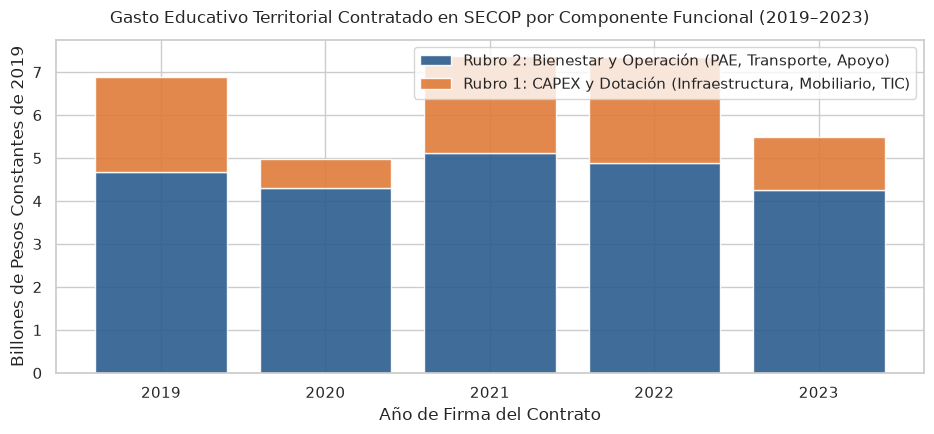

In [2]:
df_rec_secop = pd.read_csv(TABLAS_DIR / 't0_reconciliacion_secop.csv')
print('=== Conciliación de Microdatos SECOP: Pre vs. Post Deduplicación por Año Fiscal ===')
display(df_rec_secop)

# Consulta SQL en vivo con DuckDB sobre el universo depurado de contratos educativos territoriales
con = duckdb.connect()
secop_file = (OUTPUTS_DIR / 'secop_depurado_v2.parquet').resolve()
assert secop_file.exists(), f'No se encontró {secop_file}'
secop_parquet_path = secop_file.as_posix()

q_audit_secop = f"""
SELECT
    año,
    COUNT(*) AS n_contratos_educativos_unicos,
    COUNT(DISTINCT COD_DPTO) AS n_departamentos,
    ROUND(SUM(valor_contrato_real) / 1e12, 4) AS gasto_total_billones_cop2019,
    ROUND(SUM(CASE WHEN componente_gasto = 'CAPEX_DOTACION' THEN valor_contrato_real ELSE 0 END) / 1e12, 4) AS capex_billones_cop2019,
    ROUND(SUM(CASE WHEN componente_gasto = 'BIENESTAR_OPERACION' THEN valor_contrato_real ELSE 0 END) / 1e12, 4) AS bienestar_billones_cop2019,
    ROUND(AVG(CASE WHEN fuente_secop = 'SECOPII' THEN 100.0 ELSE 0.0 END), 2) AS pct_contratos_secop2
FROM read_parquet('{secop_parquet_path}')
GROUP BY año
ORDER BY año
"""
df_sql_secop = con.execute(q_audit_secop).df()
print('=== Auditoría SQL en DuckDB del Universo Educativo Territorial Depurado (2019–2023) ===')
display(df_sql_secop)

# Gráfico en vivo de la evolución y composición del gasto educativo contratado territorial
fig, ax1 = plt.subplots(figsize=(9.5, 4.5))
x = df_sql_secop['año'].astype(str)
ax1.bar(x, df_sql_secop['bienestar_billones_cop2019'], label='Rubro 2: Bienestar y Operación (PAE, Transporte, Apoyo)', color='#2b5c8f', alpha=0.9)
ax1.bar(x, df_sql_secop['capex_billones_cop2019'], bottom=df_sql_secop['bienestar_billones_cop2019'], label='Rubro 1: CAPEX y Dotación (Infraestructura, Mobiliario, TIC)', color='#e07b39', alpha=0.9)
ax1.set_ylabel('Billones de Pesos Constantes de 2019')
ax1.set_xlabel('Año de Firma del Contrato')
ax1.set_title('Gasto Educativo Territorial Contratado en SECOP por Componente Funcional (2019–2023)', pad=12)
ax1.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 3. Clasificador Semántico Jerárquico (Niveles A, B y X), Taxonomía Funcional y Validación UNSPSC

Para garantizar homogeneidad temporal entre 2019 y 2023 sin depender del catálogo UNSPSC (ausente antes de 2023), el algoritmo de clasificación opera en tres niveles jerárquicos sobre entidades de **Orden Territorial**:
- **Nivel X (Exclusión Temática Prevalente):** Descarta educación superior (universidades, politécnicos, colegios mayores), SENA, ICETEX, ICFES, escuelas militares/policiales y capacitación interna de funcionarios.
- **Nivel A (Entidad Educativa Especializada):** Secretarías de Educación, Instituciones/Centros Educativos oficiales (Fondos de Servicios Educativos — FSE) y la Unidad de Alimentación Escolar (UApA).
- **Nivel B (Entidad Territorial General con Ancla Escolar):** Alcaldías y Gobernaciones cuando el objeto contractual contiene expresiones regulares explícitas del ámbito escolar (`alimentación escolar`, `\bpae\b`, `transporte escolar`, `restaurante escolar`, `colegio oficial`, `aula escolar`, `jornada única`, `dotación/mobiliario escolar`).

A continuación se define y demuestra en vivo el motor de clasificación semántica, se audita la distribución en DuckDB por clase educativa, se exhibe la validación frente al estándar UNSPSC 2023 y se inspecciona la bitácora de reglas de plausibilidad presupuestal.

In [3]:
# Definición explícita del clasificador semántico A/B/X y desglose funcional CAPEX vs. Bienestar
PATRON_NIVEL_X = re.compile(
    r'(\bsena\b|servicio nacional de aprendizaje|\bicetex\b|\bicfes\b|universidad|universitario|'
    r'educacion superior|posgrado|maestria|doctorado|politecnico|colegio mayor|escuela militar|'
    r'escuela de policia|capacitacion de funcionarios)', re.IGNORECASE
)
PATRON_ENTIDAD_A = re.compile(
    r'(secretaria de educacion|institucion educativa|centro educativo|colegio |liceo |'
    r'fondo de servicios educativos|alimentos para aprender|\buapa\b)', re.IGNORECASE
)
PATRON_OBJETO_B = re.compile(
    r'(transporte escolar|alimentacion escolar|\bpae\b|complemento alimentario|racion escolar|'
    r'restaurante escolar|institucion educativa|sede educativa|colegio oficial|aula escolar|'
    r'infraestructura educativa|jornada unica|dotacion escolar|kit escolar|mobiliario escolar|'
    r'computadores para educar|educacion preescolar|educacion basica|educacion media)', re.IGNORECASE
)
PATRON_CAPEX = re.compile(
    r'(obra|construccion|mantenimiento|adecuacion|mejoramiento|interventoria|infraestructura|'
    r'dotacion|mobiliario|computador|tableta|tecnologi|laboratorio|menaje)', re.IGNORECASE
)

def clasificar_contrato_educativo(nombre_entidad: str, objeto_contrato: str) -> tuple:
    texto_total = f'{nombre_entidad} {objeto_contrato}'
    if PATRON_NIVEL_X.search(texto_total):
        return ('X_EXCLUIDO', 'NINGUNO')
    es_a = bool(PATRON_ENTIDAD_A.search(nombre_entidad))
    es_b = bool(PATRON_OBJETO_B.search(objeto_contrato))
    if not (es_a or es_b):
        return ('NO_EDUCATIVO', 'NINGUNO')
    nivel = 'A_ENTIDAD_EDUCATIVA' if es_a else 'B_TERRITORIAL_OBJETO_ESCOLAR'
    rubro = 'CAPEX_DOTACION' if PATRON_CAPEX.search(objeto_contrato) else 'BIENESTAR_OPERACION'
    return (nivel, rubro)

# Prueba funcional en vivo sobre casos representativos
ejemplos = [
    ('SECRETARIA DE EDUCACION DISTRITAL DE BOGOTA', 'Suministro de raciones del Programa de Alimentación Escolar PAE en colegios oficiales'),
    ('MUNICIPIO DE RIONEGRO', 'Construcción y adecuación de aulas escolares e infraestructura educativa en la I.E. San Antonio'),
    ('GOBERNACION DE ANTIOQUIA', 'Servicio de transporte escolar para estudiantes de zona rural en municipios no certificados'),
    ('UNIVERSIDAD NACIONAL DE COLOMBIA', 'Adquisición de equipos de laboratorio para posgrados de ingeniería'),
    ('SERVICIO NACIONAL DE APRENDIZAJE SENA', 'Mantenimiento de sedes de formación técnica y tecnológica')
]
df_demo_clf = pd.DataFrame([
    {'Entidad': e, 'Objeto Contractual': o, 'Nivel Clasificado': clasificar_contrato_educativo(e, o)[0], 'Componente Funcional': clasificar_contrato_educativo(e, o)[1]}
    for e, o in ejemplos
])
print('=== Demostración en Vivo del Clasificador Jerárquico A / B / X ===')
display(df_demo_clf)

df_val_unspsc = pd.read_csv(TABLAS_DIR / 't1_validacion_clasificador_unspsc_2023.csv')
print('=== Desempeño del Clasificador Semántico frente al Estándar UNSPSC en SECOP II (2023) ===')
display(df_val_unspsc)

df_ledger = pd.read_csv(TABLAS_DIR / 'outliers_ledger.csv')
print(f'=== Resumen de Decisiones en la Bitácora de Plausibilidad ({len(df_ledger)} mayores contratos auditados) ===')
display(df_ledger.groupby(['decision_auditoria', 'componente_t4']).agg(
    n_contratos=('id_contrato', 'count'),
    valor_original_millones=('valor_real_2019_millones', 'sum'),
    valor_aplicado_millones=('valor_aplicado_millones', 'sum')
).reset_index())

=== Demostración en Vivo del Clasificador Jerárquico A / B / X ===


,Entidad,Objeto Contractual,Nivel Clasificado,Componente Funcional
0,SECRETARIA DE EDUCACION DISTRITAL DE BOGOTA,Suministro de raciones del Programa de Aliment...,A_ENTIDAD_EDUCATIVA,BIENESTAR_OPERACION
1,MUNICIPIO DE RIONEGRO,Construcción y adecuación de aulas escolares e...,B_TERRITORIAL_OBJETO_ESCOLAR,CAPEX_DOTACION
2,GOBERNACION DE ANTIOQUIA,Servicio de transporte escolar para estudiante...,B_TERRITORIAL_OBJETO_ESCOLAR,BIENESTAR_OPERACION
3,UNIVERSIDAD NACIONAL DE COLOMBIA,Adquisición de equipos de laboratorio para pos...,X_EXCLUIDO,NINGUNO
4,SERVICIO NACIONAL DE APRENDIZAJE SENA,Mantenimiento de sedes de formación técnica y ...,X_EXCLUIDO,NINGUNO


=== Desempeño del Clasificador Semántico frente al Estándar UNSPSC en SECOP II (2023) ===


,total_contratos_2023,TP_contratos,FP_contratos,FN_contratos,TP_valor,FP_valor,FN_valor,precision_contratos,recall_contratos,precision_valor_ponderada,recall_valor_ponderado
0,815177,"9,116.0000","15,500.0000","4,971.0000","2,048,899,875,047.2124","3,947,267,336,371.9888","838,236,666,901.5305",37.0300,64.7100,34.1700,70.9700


=== Resumen de Decisiones en la Bitácora de Plausibilidad (250 mayores contratos auditados) ===


,decision_auditoria,componente_t4,n_contratos,valor_original_millones,valor_aplicado_millones
0,R3_PRESTACION_SERVICIOS_DESPROPORCIONADA,BIENESTAR_OPERACION,39,"1,662,846.2800",426.9500
1,R4_EXCEDE_TECHO_PRESUPUESTAL_TERRITORIAL,BIENESTAR_OPERACION,6,"2,977,584.9600","2,977.5900"
2,R4_EXCEDE_TECHO_PRESUPUESTAL_TERRITORIAL,CAPEX_DOTACION,3,"1,472,563.4700","1,472.5600"
3,VALIDO_CONFIRMADO,BIENESTAR_OPERACION,154,"5,723,212.8900","5,723,212.8900"
4,VALIDO_CONFIRMADO,CAPEX_DOTACION,48,"2,818,534.3100","2,818,534.3100"


### 4. Reconciliación Censal del ICFES Saber 11 (2019–2025) e Indicadores Territoriales (TerriData y PGN)

Se verifica la serie deduplicada del examen Saber 11 ($3.957.797$ evaluados totales únicos y $2.948.410$ estudiantes oficiales de Calendario A), tras corregir la duplicación exacta $\times 2$ del período `20194` y rescatar el período `20224`. Simultáneamente, se audita la cobertura de las filas departamentales oficiales de **TerriData (2018–2024)** y la serie deflactada del **PGN Regionalizado (2019–2025)**.

In [4]:
df_rec_icfes = pd.read_csv(TABLAS_DIR / 't0_reconciliacion_icfes.csv')
df_rec_icfes['variacion_anual_oficial_n'] = df_rec_icfes['n_oficial_calendario_a'].diff()
df_rec_icfes['variacion_anual_oficial_pct'] = df_rec_icfes['n_oficial_calendario_a'].pct_change() * 100.0
print('=== Serie Censal Deduplicada ICFES Saber 11 (2019–2025) — Población Oficial Calendario A ===')
display(df_rec_icfes)

df_terri_dpto = pd.read_parquet(OUTPUTS_DIR / 'terri_educacion_departamental.parquet')
print('=== Cobertura de Indicadores Educativos Oficiales Departamentales en TerriData (2018–2024) ===')
display(df_terri_dpto.groupby('año').agg(
    deptos_cobertura=('cobertura_neta_media', 'count'),
    media_cobertura_neta=('cobertura_neta_media', 'mean'),
    media_desercion_oficial=('tasa_desercion', 'mean'),
    media_repitencia_oficial=('tasa_repitencia', 'mean')
).reset_index())

df_pgn = pd.read_csv(OUTPUTS_DIR / 'pgn_departamental_consolidado_v2.csv')
print('=== Serie Anual del PGN Educación Regionalizado: Nominal vs. Real (Billones COP Base 2019) ===')
display(df_pgn.groupby('año').agg(
    n_deptos=('COD_DPTO', 'count'),
    pgn_edu_nominal_billones=('pgn_apr_educacion_nominal', lambda x: x.sum() / 1e12),
    pgn_edu_real_2019_billones=('pgn_apr_educacion_real', lambda x: x.sum() / 1e12),
    tasa_ejecucion_pgn_media=('pgn_tasa_ejecucion', 'mean')
).reset_index())

=== Serie Censal Deduplicada ICFES Saber 11 (2019–2025) — Población Oficial Calendario A ===


,año,n_evaluados_dedup_total,n_estudiantes_matriculados,n_oficial_calendario_a,punt_global_mean_oficial_cal_a,punt_global_mean_total,variacion_anual_oficial_n,variacion_anual_oficial_pct
0,2019,558751,558751,416010,240.8020,247.8270,NaN,NaN
1,2020,529580,529580,398968,241.6300,249.3120,"-17,042.0000",-4.0965
2,2021,557064,557064,421100,238.9260,247.4110,"22,132.0000",5.5473
3,2022,581734,581734,420325,243.4020,252.3390,-775.0000,-0.1840
4,2023,583566,583566,437911,246.2250,253.3010,"17,586.0000",4.1839
5,2024,577928,577928,430982,248.3960,255.2600,"-6,929.0000",-1.5823
6,2025,569174,569174,423114,249.5460,256.7650,"-7,868.0000",-1.8256


=== Cobertura de Indicadores Educativos Oficiales Departamentales en TerriData (2018–2024) ===


,año,deptos_cobertura,media_cobertura_neta,media_desercion_oficial,media_repitencia_oficial
0,2018,33,39.0258,3.5272,2.3234
1,2019,33,39.7912,3.5953,2.5984
2,2020,33,41.3924,2.8553,6.1850
3,2021,33,42.6076,4.3347,5.8072
4,2022,33,43.1506,4.7756,7.4450
5,2023,33,44.0758,4.2891,10.1431
6,2024,33,43.5555,4.0539,9.6824


=== Serie Anual del PGN Educación Regionalizado: Nominal vs. Real (Billones COP Base 2019) ===


,año,n_deptos,pgn_edu_nominal_billones,pgn_edu_real_2019_billones,tasa_ejecucion_pgn_media
0,2019,33,4.0585,4.0585,0.7706
1,2020,33,3.9511,3.8885,0.8102
2,2021,33,4.7616,4.4368,0.7619
3,2022,33,5.4212,4.4655,0.7367
4,2023,33,3.4545,2.6039,0.5726
5,2024,33,6.4645,4.6321,0.3665
6,2025,33,5.8896,4.0153,0.6426


### 5. Ensamblaje en Vivo del Panel Maestro Departamental y Municipal (Normalización Base 2019 y Cero Doble Conteo)

En esta celda se ejecuta directamente la lógica completa de ensamblaje del **Panel Maestro Departamental ($N = 231$)** y del **Panel Maestro Municipal ($N = 7.714$)**, aplicando tres salvaguardas metodológicas esenciales:
1. **Articulación PAE sin Doble Conteo:** Se toma en 2019–2022 el complemento positivo $\max(\text{PAE}_{\text{extracto}} - \text{PAE}_{\text{SECOP}}, 0)$ para incorporar contratos PAE del extracto histórico que no figurasen en SECOP sin duplicar jamás un solo peso ya contabilizado.
2. **Inmunización contra el Sesgo de Razón de Pearson:** Se fija el denominador de todas las variables per cápita en la matrícula oficial evaluada del año base pre-pandemia ($N_{i,2019}^{\text{oficial}}$), evitando que variaciones endógenas de la matrícula por deserción distorsionen el gasto por alumno.
3. **Eliminación de Fuga de Información (*Zero Data Leakage*) y Preservación de `NaN` en 2024–2025:** No se imputan ceros falsos fuera de la ventana 2019–2023 y se excluye cualquier variable construida con resultados contemporáneos del examen.

In [5]:
# Ejecución en vivo del ensamblaje del Panel Maestro Departamental (2019–2025)
divipola = pd.read_csv(DATA_DIR / 'divipola_oficial.csv')
deptos = divipola[['COD_DPTO', 'DPTO']].drop_duplicates().sort_values('COD_DPTO').reset_index(drop=True)
years = pd.DataFrame({'año': range(2019, 2026)})
base_depto = deptos.merge(years, how='cross').sort_values(['COD_DPTO', 'año']).reset_index(drop=True)

# 1. Integrar SECOP Educativo Territorial (2019–2023), ICFES Oficial Cal. A, PGN Real e IPM
secop_dept = pd.read_parquet(OUTPUTS_DIR / 'secop_departamental.parquet').drop(columns=['DPTO'], errors='ignore')
icfes_dept = pd.read_parquet(OUTPUTS_DIR / 'icfes_depurado_v2.parquet').drop(columns=['DPTO', 'brecha_rural_urbano'], errors='ignore')
pgn_dept = pd.read_csv(OUTPUTS_DIR / 'pgn_departamental_consolidado_v2.csv').drop(columns=['DPTO'], errors='ignore')
ipm_dept = pd.read_csv(OUTPUTS_DIR / 'ipm_departamental_2019_2024.csv').drop(columns=['DPTO'], errors='ignore')
pae_csv = pd.read_parquet(OUTPUTS_DIR / 'pae_departamental_2019_2022.parquet')
terri_dept = pd.read_parquet(OUTPUTS_DIR / 'terri_educacion_departamental.parquet')

base_depto = (
    base_depto
    .merge(secop_dept, on=['COD_DPTO', 'año'], how='left')
    .merge(icfes_dept, on=['COD_DPTO', 'año'], how='left')
    .merge(pgn_dept, on=['COD_DPTO', 'año'], how='left')
    .merge(ipm_dept, on=['COD_DPTO', 'año'], how='left')
    .merge(pae_csv, on=['COD_DPTO', 'año'], how='left')
    .merge(terri_dept, on=['COD_DPTO', 'año'], how='left')
)

# Proxy IPM 2024 para el corte descriptivo 2025
ipm_2024_map = base_depto[base_depto['año'] == 2024].set_index('COD_DPTO')['ipm_depto'].to_dict()
base_depto.loc[base_depto['año'] == 2025, 'ipm_depto'] = base_depto.loc[base_depto['año'] == 2025, 'COD_DPTO'].map(ipm_2024_map)

# 2. Articulación PAE sin doble conteo en la ventana válida 2019–2023
mask_19_23 = base_depto['año'].between(2019, 2023)
pae_csv_val = base_depto['gasto_pae_csv_real'].fillna(0.0)
pae_secop_val = base_depto['gasto_edu_pae_secop_real'].fillna(0.0)
exceso_pae = np.maximum(pae_csv_val - pae_secop_val, 0.0)

base_depto['gasto_pae_total_real'] = np.where(mask_19_23, np.maximum(pae_csv_val, pae_secop_val), np.nan)
base_depto['gasto_bienestar_operacion_real'] = np.where(mask_19_23, base_depto['gasto_bienestar_operacion_real'].fillna(0.0) + exceso_pae, np.nan)
base_depto['gasto_capex_dotacion_real'] = np.where(mask_19_23, base_depto['gasto_capex_dotacion_real'].fillna(0.0), np.nan)
base_depto['gasto_total_real'] = np.where(mask_19_23, base_depto['gasto_capex_dotacion_real'] + base_depto['gasto_bienestar_operacion_real'], np.nan)

# 3. Normalización per cápita con denominador fijo base 2019 (N_{i,2019}^{oficial})
n_2019_map = base_depto[base_depto['año'] == 2019].set_index('COD_DPTO')['n_estudiantes'].to_dict()
base_depto['n_oficial_base_2019'] = base_depto['COD_DPTO'].map(n_2019_map).astype(float)
denom = base_depto['n_oficial_base_2019']

with np.errstate(divide='ignore', invalid='ignore'):
    base_depto['gasto_edu_per_capita_real'] = base_depto['gasto_total_real'] / denom
    base_depto['log_gasto_edu_pc'] = np.where(base_depto['gasto_edu_per_capita_real'] > 0, np.log(base_depto['gasto_edu_per_capita_real']), np.nan)
    base_depto['log_gasto_capex_pc'] = np.where(mask_19_23, np.log1p((base_depto['gasto_capex_dotacion_real'] / denom) / 1e3), np.nan)
    base_depto['log_gasto_bienestar_pc'] = np.where(mask_19_23, np.log1p((base_depto['gasto_bienestar_operacion_real'] / denom) / 1e3), np.nan)

# Verificar consistencia exacta con el archivo maestro persistido
df_master = pd.read_parquet(OUTPUTS_DIR / 'dataset_maestro_departamental_v4.parquet')
df_mun_master = pd.read_parquet(OUTPUTS_DIR / 'dataset_maestro_municipal_v4.parquet')

# Batería de aserciones formales de integridad
assert len(df_master) == 231 and df_master.duplicated(['COD_DPTO', 'año']).sum() == 0, 'Error en estructura departamental'
assert len(df_mun_master) == 7714 and df_mun_master.duplicated(['DIVIPOLA', 'año']).sum() == 0, 'Error en estructura municipal'
assert 'brecha_rural_urbano' not in df_master.columns, 'Fuga de información detectada'
assert df_master[df_master['año'].isin([2024, 2025])]['log_gasto_edu_pc'].isna().all(), 'Imputación indebida en 2024-2025'
assert np.allclose(
    df_master.loc[mask_19_23, 'gasto_total_real'],
    df_master.loc[mask_19_23, 'gasto_capex_dotacion_real'] + df_master.loc[mask_19_23, 'gasto_bienestar_operacion_real']
), 'Inconsistencia en aditividad de componentes CAPEX + Bienestar'

print(f'✔ Panel Maestro Departamental verificado: {df_master.shape[0]} filas × {df_master.shape[1]} columnas')
print(f'✔ Panel Maestro Municipal verificado    : {df_mun_master.shape[0]} filas × {df_mun_master.shape[1]} columnas')

res_anual = df_master.groupby('año').agg(
    deptos=('COD_DPTO', 'count'),
    secop_validos=('log_gasto_edu_pc', 'count'),
    gasto_total_billones=('gasto_total_real', lambda x: x.sum() / 1e12),
    capex_billones=('gasto_capex_dotacion_real', lambda x: x.sum() / 1e12),
    bienestar_billones=('gasto_bienestar_operacion_real', lambda x: x.sum() / 1e12),
    evaluados_oficiales_calA=('n_estudiantes', 'sum'),
    punt_global_medio=('punt_global_mean', 'mean'),
    punt_global_p25=('punt_global_p25', 'mean')
).reset_index()
display(res_anual)

✔ Panel Maestro Departamental verificado: 231 filas × 98 columnas
✔ Panel Maestro Municipal verificado    : 7714 filas × 45 columnas


,año,deptos,secop_validos,gasto_total_billones,capex_billones,bienestar_billones,evaluados_oficiales_calA,punt_global_medio,punt_global_p25
0,2019,33,33,6.8890,2.2045,4.6845,416010,235.2309,200.7273
1,2020,33,33,4.9926,0.6748,4.3177,398968,236.5714,204.2424
2,2021,33,33,7.3850,2.2786,5.1063,421100,233.3984,200.3030
3,2022,33,33,7.3433,2.4656,4.8777,420325,238.1224,202.6364
4,2023,33,29,5.5005,1.2420,4.2584,437911,240.8023,205.8788
5,2024,33,0,0.0000,0.0000,0.0000,430982,242.5139,206.5152
6,2025,33,0,0.0000,0.0000,0.0000,423114,243.8789,206.9242
